## PaPaGei reproduction on the PPG-BP dataset

This notebook reproduces and examines PaPaGei results for blood pressure
regression, heart-rate regression and normal versus non-normal blood
pressure classification.

The implementation is adapted from the authors’ released example notebook.
The analysis focuses on PaPaGei-S and PaPaGei-P, with additional comparisons
against simple baselines, random forests and MOMENT.

#### Experimental setups

- **Original 205-participant setup:** the released participant splits and
  notebook regularisation grid are used, with 123 training participants
  and 82 participants in the combined validation–test set.
- **205-participant rerun:** the same splits are retained, but the Ridge
  regularisation grid is restricted to the values specified in the paper.
- **Adapted 219-participant setup:** all participants are included, six
  within-participant duplicate recordings are removed, and participants
  sharing a recording are kept together. The split contains 131 training,
  44 validation and 44 test participants. Grouped cross-validation is used.


#### Notebook contents

1. Environment and paths
2. Data inspection and preprocessing
3. PaPaGei embedding extraction
4. Original regression reproduction
5. Investigation of reproduction discrepancies
6. Adapted 219-participant evaluation
7. Classification reproduction
8. Baseline comparisons
9. Summary tables and figures

Hyperparameter selection is performed within the training set.
Unless stated otherwise, final evaluation uses the combined validation
and test sets. Saved results are used to construct the report’s tables
and figures.

All recomputation flags are `False` by default. This notebook presents the results and offers selected verification reruns - the original notebook remains the full reproduction record. Reflections describe the saved experiments and must be checked again after a rerun.

### 1. Environment and paths

Run this notebook from the repository root using the project environment.
The following cells check the Python environment, import dependencies
and define the data and output locations.

In [ ]:
%pip install dotmap
%pip install vitaldb 
%pip install pyPPG==1.0.41
%pip install openpyxl
%pip install torch_ecg
%pip install "matplotlib-inline==0.1.6"

In [ ]:
#shared imports - loads packages and original repository helpers needed by later cells. 

import os
import sys
import hashlib
from pathlib import Path

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    GroupShuffleSplit,
    GroupKFold,
    StratifiedGroupKFold
)
from sklearn.metrics import (
    mean_absolute_error,
    roc_auc_score,
    accuracy_score,
    f1_score
)

from torch_ecg._preprocessors import Normalize
from models.resnet import ResNet1D, ResNet1DMoE
from preprocessing.ppg import preprocess_one_ppg_signal
from segmentations import waveform_to_segments, save_segments_to_directory

from linearprobing.utils import (
    resample_batch_signal,
    load_model_without_module_prefix,
    get_data_for_ml,
    extract_labels,
    bootstrap_metric_confidence_interval
)
from linearprobing.feature_extraction_papagei import save_embeddings
from linearprobing.extracted_feature_combine import segment_avg_to_dict
from linearprobing.regression import regression_model

from evaluation_utils import evaluate_features
from baselines.statistical_features import compute_signal_statistics_df

In [ ]:
#dataset directory defined relative to the repository root.
download_dir = Path("./data_PPG")

#original participant metadata are loaded.
raw_metadata = pd.read_excel(
    download_dir / "Data File" / "PPG-BP dataset.xlsx",
    header=1
)

Execution switches and shared labels, defines paths, model names, targets and flags. `False` loads saved artefacts, while `True` runs the named stage when its cell is executed.

In [ ]:


#existing input and result locations are used.
data_dir = Path(download_dir) / "Data File"
experiment_dir = Path(download_dir) / "reproduction_219_seed42"
results_219_dir = Path("results") / "reproduction_219_seed42"
baseline_results_dir = Path("results") / "baselines"
classification_205_dir = Path("results") / "classification_205_released"

#saved results are used unless a computation is enabled.
RECOMPUTE_RELEASED_PREPROCESSING = False
RECOMPUTE_RELEASED_EMBEDDINGS = False
RECOMPUTE_ORIGINAL_REGRESSION = False
recompute_rerun = False
recompute_scaling = False
recompute_duplicate_check = False
REBUILD_219_SPLIT = False
RECOMPUTE_219_EMBEDDINGS = False
RECOMPUTE_NESTED_CV = False
RECOMPUTE_219_REGRESSION = False
RECOMPUTE_CLASSIFICATION = False
RECOMPUTE_STATISTICAL_FEATURES = False
RECOMPUTE_RF_REGRESSION = False
RECOMPUTE_RF_CLASSIFICATION = False
RECOMPUTE_MOMENT_MODELS = False

#original labels are retained separately.
labels = raw_metadata.copy()
label_data = labels.rename(columns={
    "Systolic Blood Pressure(mmHg)": "sysbp",
    "Diastolic Blood Pressure(mmHg)": "diasbp",
    "Heart Rate(b/m)": "hr"
})

models = ["papagei_s", "papagei_p"]
bp_targets = ["sysbp", "diasbp"]

### 2. Data inspection and preprocessing

- **(a)**: Download the PPG-BP data from [PPG-BP Database](https://figshare.com/articles/dataset/PPG-BP_Database_zip/5459299) to a directory.
  - Add the download path to `download_dir`.
- **(b)**: Use the download path for further pre-processing.
- **(c)**: Use pre-defined user splits for later linear evaluation

The metadata and an example recording are inspected below. Recordings are
then normalised, filtered, resampled to 125 Hz and zero-padded to 1250
samples. The released participant splits are loaded for the original
205-participant setup.

#### 2.1 (a) Dataset inspection

In [16]:
df = pd.read_excel(f"{download_dir}/Data File/PPG-BP dataset.xlsx", header=1)

In [ ]:
#working copy is used so the original column names remain available.
df = raw_metadata.copy()

In [ ]:
#visualising data spreadsheet
print("Rows and columns:", df.shape)
print("Unique participants:", df["subject_ID"].nunique())
display(df.head())

Rows and columns: (219, 14)
Unique participants: 219


,Num.,subject_ID,Sex(M/F),Age(year),Height(cm),Weight(kg),Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m),BMI(kg/m^2),Hypertension,Diabetes,cerebral infarction,cerebrovascular disease
0,1,2,Female,45,152,63,161,89,97,27.268006,Stage 2 hypertension,NaN,NaN,NaN
1,2,3,Female,50,157,50,160,93,76,20.284799,Stage 2 hypertension,NaN,NaN,NaN
2,3,6,Female,47,150,47,101,71,79,20.888889,Normal,NaN,NaN,NaN
3,4,8,Male,45,172,65,136,93,87,21.971336,Prehypertension,NaN,NaN,NaN
4,5,9,Female,46,155,65,123,73,73,27.055151,Prehypertension,NaN,NaN,NaN


**Example raw waveform.** Loads one recording and plots amplitude against seconds

Signal shape: (2100,)
Duration: 2.1 seconds


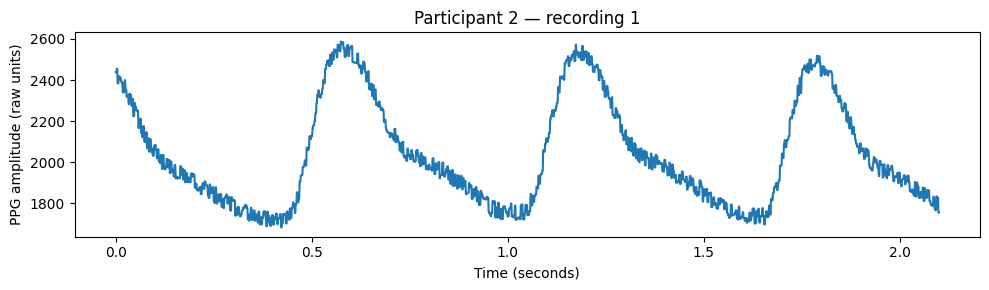

In [ ]:
#visualising PPG waveform
signal_path = (
    f"{download_dir}/Data File/0_subject/2_1.txt"
)

raw_signal = pd.read_csv(
    signal_path, sep="\t", header=None
).values.squeeze()

#removing the last entry according to the authors
signal = raw_signal[:-1]

fs = 1000  # samples per second
time = np.arange(len(signal)) / fs

print("Signal shape:", signal.shape)
print("Duration:", len(signal) / fs, "seconds")

plt.figure(figsize=(10, 3))
plt.plot(time, signal)
plt.xlabel("Time (seconds)")
plt.ylabel("PPG amplitude (raw units)")
plt.title("Participant 2 — recording 1")
plt.tight_layout()
plt.show()

**Example preprocessing.** Normalises and filters the example, then plots both stages.

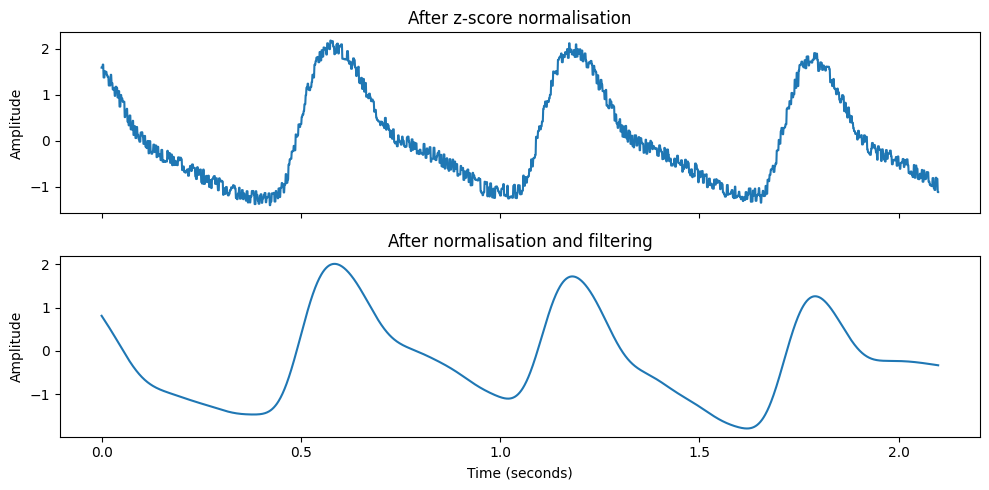

In [ ]:
norm = Normalize(method="z-score")

normalized_signal, _ = norm.apply(signal.copy(), fs=fs)

filtered_signal, _, _, _ = preprocess_one_ppg_signal(
    waveform=normalized_signal,
    frequency=fs
)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(time, normalized_signal)
axes[0].set_title("After z-score normalisation")
axes[0].set_ylabel("Amplitude")

axes[1].plot(time, filtered_signal)
axes[1].set_title("After normalisation and filtering")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

**Signal locations and sampling rates.** Defines the raw/processed directories and the original and target sampling rates.

In [ ]:
subjects = df.subject_ID.values
main_dir = f"{download_dir}/Data File/0_subject/"
ppg_dir = f"{download_dir}/Data File/ppg/"

if not os.path.exists(ppg_dir):
    os.mkdir(ppg_dir)
    
fs = 1000 
fs_target = 125

#### 2.2 (b) Preprocessing all recordings

In [ ]:
#unique IDs prevent the same three recordings being processed three times.
filenames = sorted({path.stem.split("_")[0] for path in Path(main_dir).glob("*.txt")}, key=int)

In [ ]:
#true recreates intermediate signal files; existing files are overwritten.
if RECOMPUTE_RELEASED_PREPROCESSING:
    #normalising by subtracting mean and and dividing by std
    norm = Normalize(method='z-score')

    #filtering, resampling and padding 
    for f in tqdm(filenames):
        segments = []
        for s in range(1, 4):
            signal = pd.read_csv(f"{main_dir}{f}_{str(s)}.txt", sep='\t', header=None)
            signal = signal.values.squeeze()[:-1]
            signal, _ = norm.apply(signal, fs=fs)
            signal, _, _, _ = preprocess_one_ppg_signal(waveform=signal,
                                                    frequency=fs)
            signal = resample_batch_signal(signal, fs_original=fs, fs_target=fs_target, axis=0)
        
            padding_needed = 1250 - len(signal)
            assert padding_needed >= 0
            pad_left = padding_needed // 2
            pad_right = padding_needed - pad_left
        
            signal = np.pad(signal, pad_width=(pad_left, pad_right))
            segments.append(signal)
        segments = np.vstack(segments)
        child_dir = f.zfill(4)
        save_segments_to_directory(save_dir=ppg_dir,
                                  dir_name=child_dir,
                                  segments=segments)
else:
    assert Path(ppg_dir).is_dir(), "Run the original preprocessing or enable this stage first."
    print("Existing preprocessed recordings are retained.")

#### 2.3 (c) Released participant splits

In [ ]:
df = df.rename(columns={"Sex(M/F)": "sex",
                   "Age(year)": "age",
                   "Systolic Blood Pressure(mmHg)": "sysbp",
                   "Diastolic Blood Pressure(mmHg)": "diasbp",
                   "Heart Rate(b/m)": "hr",
                   "BMI(kg/m^2)": "bmi"})
#required targets must not be replaced with artificial zero-valued labels.
assert df[["subject_ID", "sysbp", "diasbp", "hr", "Hypertension"]].notna().all().all()
df = df.fillna(0)

**Released split reconstruction.** Retains the authors’ hard-coded participant lists and constructs the 123/41/41 data tables in memory.

In [ ]:
#participant IDs are retained from the authors' released example notebook
#the same splits are used for the original 205-participant reproduction

train_ids = [  2,   6,   8,  10,  12,  15,  16,  17,  18,  19,  22,  23,  26,
        31,  32,  34,  35,  38,  40,  45,  48,  50,  53,  55,  56,  58,
        60,  61,  63,  65,  66,  83,  85,  87,  89,  92,  93,  97,  98,
        99, 100, 104, 105, 106, 107, 112, 113, 114, 116, 120, 122, 126,
       128, 131, 134, 135, 137, 138, 139, 140, 141, 146, 148, 149, 152,
       153, 154, 158, 160, 162, 164, 165, 167, 169, 170, 175, 176, 179,
       183, 184, 186, 188, 189, 190, 191, 193, 196, 197, 199, 205, 206,
       207, 209, 210, 212, 216, 217, 218, 223, 226, 227, 230, 231, 233,
       234, 240, 242, 243, 244, 246, 247, 248, 256, 257, 404, 407, 409,
       412, 414, 415, 416, 417, 419]

test_ids = [14,  21,  25,  51,  52,  62,  67,  86,  90,  96, 103, 108, 110,
       119, 123, 124, 130, 142, 144, 157, 172, 173, 174, 180, 182, 185,
       192, 195, 200, 201, 211, 214, 219, 221, 228, 239, 250, 403, 405,
       406, 410]

val_ids = [3,  11,  24,  27,  29,  30,  41,  43,  47,  64,  88,  91,  95,
       115, 125, 127, 136, 145, 155, 156, 161, 163, 166, 178, 198, 203,
       208, 213, 215, 222, 229, 232, 235, 237, 241, 245, 252, 254, 259,
       411, 418]

df_train = df[df.subject_ID.isin(train_ids)]
df_val = df[df.subject_ID.isin(val_ids)]
df_test = df[df.subject_ID.isin(test_ids)]

#integer-ID copies are retained for reuse without writing split CSVs.
original_splits = {"train": df_train.copy(), "val": df_val.copy(), "test": df_test.copy()}

**Split overlap check.** Counts participant IDs and their intersections, then lists unassigned participants

In [10]:
train = set(df_train["subject_ID"])
val = set(df_val["subject_ID"])
test = set(df_test["subject_ID"])

print("Participants:")
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

print("\nOverlapping participants:")
print("Train / validation:", len(train & val))
print("Train / test:", len(train & test))
print("Validation / test:", len(val & test))

assigned = train | val | test
all_participants = set(df["subject_ID"])

print("\nParticipants not assigned:", sorted(all_participants - assigned))

Participants:
Train: 123
Validation: 41
Test: 41

Overlapping participants:
Train / validation: 0
Train / test: 0
Validation / test: 0

Participants not assigned: [9, 13, 54, 57, 84, 111, 150, 151, 171, 220, 224, 251, 253, 413]


The supplied participant lists contain 123 training, 41 validation and 41 test participants, with no overlap. Fourteen of the 219 participants in the metadata are not included in these lists. The reason for their exclusion has not yet been established.

### 3. PaPaGei Embedding Extraction

Pretrained PaPaGei models are loaded and used as frozen feature extractors.
An example is shown for one recording, followed by batch extraction.

Each recording produces a 512-dimensional embedding. Embeddings are
averaged across recordings from the same participant and saved separately
for the training, validation and test sets.

The signals have already been preprocessed, so normalisation and
resampling are disabled during embedding extraction.

**Embedding setup.** Sets CPU/batch settings and formats IDs as four-digit strings to match feature keys.

In [20]:
batch_size = 256
device = "cpu"
case_name = "subject_ID"
ppg_dir = f"{download_dir}/Data File/ppg/"

df_train = pd.read_csv(f"{download_dir}/Data File/train.csv")
df_val = pd.read_csv(f"{download_dir}/Data File/val.csv")
df_test = pd.read_csv(f"{download_dir}/Data File/test.csv")

df_train.loc[:, case_name] = df_train[case_name].apply(lambda x:str(x).zfill(4))
df_val.loc[:, case_name] = df_val[case_name].apply(lambda x:str(x).zfill(4))
df_test.loc[:, case_name] = df_test[case_name].apply(lambda x:str(x).zfill(4))

dict_df = {'train': df_train, 'val': df_val, 'test': df_test}

#### 3.1 Example embedding extraction

**Example encoder.** Constructs PaPaGei-S and loads its pretrained weights only if released embedding extraction is enabled.

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    model_config = {'base_filters': 32,
                'kernel_size': 3,
                'stride': 2,
                'groups': 1,
                'n_block': 18,
                'n_classes': 512,
                'n_experts': 3
                }

    model = ResNet1DMoE(in_channels=1, 
                base_filters=model_config['base_filters'], 
                kernel_size=model_config['kernel_size'],
                stride=model_config['stride'],
                groups=model_config['groups'],
                n_block=model_config['n_block'],
                n_classes=model_config['n_classes'],
                n_experts=model_config['n_experts'])

    model_path = "weights/papagei_s.pt"
    model = load_model_without_module_prefix(model, model_path)
    model.to(device)

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    # load a signal
    # note that that signal is already resampled and normalized
    signal = joblib.load(os.path.join(ppg_dir, '0002', '0.p'))
    signal = torch.Tensor(signal)
    signal = signal[None, :].unsqueeze(dim=0)
    print(f"PPG dimensions before inference : {signal.shape}")

    model.eval()
    with torch.inference_mode():
        signal = signal.to(device)
        outputs = model(signal)
        embeddings = outputs[0].cpu().detach().numpy()
    print(f"Embedding dimensions : {embeddings.shape}")

PPG dimensions before inference : torch.Size([1, 1, 1250])
Embedding dimensions : (1, 512)


#### 3.2 Batch extraction function

**Reusable batch extraction.** Defines how recordings are embedded and averaged per participant.

In [ ]:
def extract_features_and_save(model, ppg_dir, batch_size, device, output_idx, resample, normalize, fs, fs_target, content):
    #extract recording embeddings and save participant averages for each split
    for split in ['train', 'val', 'test']:
        # Choose one split at a time
        df = dict_df[split]
        save_dir = f"{download_dir}/features"

        # Creating require directory structure and names
        if not os.path.exists(f"{save_dir}"):
            os.mkdir(f"{save_dir}")
        
        model_name = model_path.split("/")[-1].split(".pt")[0]
        if not os.path.exists(f"{save_dir}/{model_name}"):
            os.mkdir(f"{save_dir}/{model_name}")
        split_dir = f"{save_dir}/{model_name}/{split}/"
        
        child_dirs = np.unique(df[case_name].values)

        # Function that extracts and saves embeddings
        save_embeddings(path=ppg_dir,
                        child_dirs=child_dirs, 
                        save_dir=split_dir, 
                        model=model, 
                        batch_size=batch_size, 
                        device=device, 
                        output_idx=output_idx,
                        resample=resample, 
                        normalize=normalize, 
                        fs=fs, 
                        fs_target=fs_target)
        
        # Compile the extracted embeddings at the patient or segment level adn save it               
        dict_feat = segment_avg_to_dict(split_dir, content)
        joblib.dump(dict_feat, f"{save_dir}/{model_name}/dict_{split}_{content}.p")

#### 3.3 PaPaGei-S embeddings

**PaPaGei-S model.** Loads the S architecture/checkpoint for optional batch extraction. It is skipped in saved-results mode.

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    model_config = {'base_filters': 32,
                'kernel_size': 3,
                'stride': 2,
                'groups': 1,
                'n_block': 18,
                'n_classes': 512,
                'n_experts': 3
                }

    model = ResNet1DMoE(in_channels=1, 
                base_filters=model_config['base_filters'], 
                kernel_size=model_config['kernel_size'],
                stride=model_config['stride'],
                groups=model_config['groups'],
                n_block=model_config['n_block'],
                n_classes=model_config['n_classes'],
                n_experts=model_config['n_experts'])

    model_path = "weights/papagei_s.pt"
    model = load_model_without_module_prefix(model, model_path)
    model.to(device)

**PaPaGei-S feature extraction.** Optionally runs the batch helper. Resampling and normalisation are disabled (preprocessing has already applied them)

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    extract_features_and_save(model=model,
                             ppg_dir=ppg_dir,
                             batch_size=batch_size,
                             device=device,
                             output_idx=0,
                             resample=False,
                             normalize=False,
                             fs=125,
                             fs_target=125,
                             content="patient"
                             )

In [ ]:
#confirming correct test/train/valid data split
feature_dir = os.path.join(download_dir, "features", "papagei_s")

for split in ["train", "val", "test"]:
    embeddings = joblib.load(
        os.path.join(feature_dir, f"dict_{split}_patient.p")
    )

    first_id = next(iter(embeddings))

    print(
        f"{split}: {len(embeddings)} participants | "
        f"embedding shape: {np.asarray(embeddings[first_id]).shape}"
    )

train: 123 participants | embedding shape: (512,)
val: 41 participants | embedding shape: (512,)
test: 41 participants | embedding shape: (512,)


#### 3.4 PaPaGei-P embeddings

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    model_config = {'base_filters': 32,
                    'kernel_size': 3,
                    'stride': 2,
                    'groups': 1,
                    'n_block': 18,
                    'n_classes': 512,
                    }

    model = ResNet1D(in_channels=1, 
                base_filters=model_config['base_filters'], 
                kernel_size=model_config['kernel_size'],
                stride=model_config['stride'],
                groups=model_config['groups'],
                n_block=model_config['n_block'],
                n_classes=model_config['n_classes'])

    model_path = "weights/papagei_p.pt"
    model = load_model_without_module_prefix(model, model_path)
    model.to(device)

In [ ]:
if RECOMPUTE_RELEASED_EMBEDDINGS:
    extract_features_and_save(model=model,
                             ppg_dir=ppg_dir,
                             batch_size=batch_size,
                             device=device,
                             output_idx=0,
                             resample=False,
                             normalize=False,
                             fs=125,
                             fs_target=125,
                             content="patient"
                             )

### 4. Original regression reproduction

PaPaGei-S and PaPaGei-P embeddings are evaluated using Ridge regression
for systolic BP, diastolic BP and heart rate.

The original 205-participant split and extended regularisation grid
are retained. Models are fitted using 123 training participants and
evaluated on the 82 validation and test participants combined.

In [ ]:
#Restores independent released-split tables 
#and aligns identifier formatting with the saved feature dictionaries.
save_dir = f"{download_dir}/features/"
df_train = pd.read_csv(f"{download_dir}/Data File/train.csv")
df_val = pd.read_csv(f"{download_dir}/Data File/val.csv")
df_test = pd.read_csv(f"{download_dir}/Data File/test.csv")

df_train.loc[:, case_name] = df_train[case_name].apply(lambda x:str(x).zfill(4))
df_val.loc[:, case_name] = df_val[case_name].apply(lambda x:str(x).zfill(4))
df_test.loc[:, case_name] = df_test[case_name].apply(lambda x:str(x).zfill(4))
                                                                          
case_name = "subject_ID"

In [ ]:
#Defines Ridge evaluation with the full alpha grid, including 1000. 
#The original helper scales before four-fold CV, 
#selects settings using MSE and evaluates test followed by validation.
def regression(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [ ]:
#Loads the six original result dictionaries, 
#including predictions, or calls the regression function.
def get_original_results(recompute=False):
    results = {}
    rows = []
    original_batch = "20261024T131741238732Z"

    for model_name in ["papagei_s", "papagei_p"]:
        for target in ["sysbp", "diasbp", "hr"]:

            if recompute:
                #results are recalculated using the existing regression function
                result = regression(
                    save_dir=save_dir,
                    model_name=model_name,
                    content="patient",
                    df_train=df_train,
                    df_val=df_val,
                    df_test=df_test,
                    case_name=case_name,
                    label=target
                )
            else:
                #the original saved results are loaded without retraining
                result = joblib.load(
                    Path("results")
                    / f"{original_batch}_{model_name}_{target}.joblib"
                )

            results[(model_name, target)] = result

            rows.append({
                "model": model_name,
                "target": target,
                "units": "bpm" if target == "hr" else "mmHg",
                "mae": result["mae"],
                "ci_lower": result["lower_bound_mae"],
                "ci_upper": result["upper_bound_mae"]
            })

    return results, pd.DataFrame(rows)

In [7]:
#the existing reported results are loaded and displayed
all_results, original_results_table = get_original_results(recompute=False)

display(original_results_table.round(3))

,model,target,units,mae,ci_lower,ci_upper
0,papagei_s,sysbp,mmHg,14.254,11.895,16.662
1,papagei_s,diasbp,mmHg,8.910,7.502,10.315
2,papagei_s,hr,bpm,4.535,3.786,5.333
3,papagei_p,sysbp,mmHg,14.307,11.882,16.560
4,papagei_p,diasbp,mmHg,8.882,7.560,10.308
5,papagei_p,hr,bpm,4.585,3.745,5.468


In [8]:
#the published MAEs are loaded
paper = pd.read_csv("results/paper_reference_results.csv")

#the six original results are matched to the published values
comparison = original_results_table.merge(
    paper.loc[
        paper["metric"] == "mae",
        [
            "model", "target", "paper_score",
            "paper_ci_lower", "paper_ci_upper"
        ]
    ],
    on=["model", "target"],
    how="left",
    validate="one_to_one"
)

#positive differences indicate higher error than the published result
comparison["mae_difference"] = (
    comparison["mae"] - comparison["paper_score"]
)

display(comparison[[
    "model", "target", "mae", "paper_score",
    "mae_difference", "ci_lower", "ci_upper",
    "paper_ci_lower", "paper_ci_upper"
]].round(4))

,model,target,mae,paper_score,mae_difference,ci_lower,ci_upper,paper_ci_lower,paper_ci_upper
0,papagei_s,sysbp,14.2535,14.39,-0.1365,11.8955,16.6615,12.53,16.45
1,papagei_s,diasbp,8.9095,8.71,0.1995,7.5022,10.3151,7.18,10.01
2,papagei_s,hr,4.5352,4.00,0.5352,3.7855,5.3325,3.34,4.67
3,papagei_p,sysbp,14.3074,13.60,0.7074,11.8816,16.5601,10.65,16.51
4,papagei_p,diasbp,8.8820,8.88,0.0020,7.5605,10.3076,7.33,10.76
5,papagei_p,hr,4.5845,3.47,1.1145,3.7451,5.4683,2.74,4.32


The original 205-participant setup produced BP MAEs close to the published
values, but the model rankings were not preserved. Both models had higher
heart-rate errors than reported. Published and reproduced confidence
intervals overlapped (but that does not mean equal performance).

The following sections investigate whether the regularisation grid,
evaluation set composition, feature scaling or dataset integrity help
explain these differences.

## 5. Investigation of reproduction discrepancies

### 5.1 Embedding extraction checks

The feature-extraction code was inspected to check whether implementation
details could explain the differences from the published results.

Embeddings are extracted for individual recordings and then averaged
per participant, raw signals are not averaged. Extraction uses evaluation
mode, with additional normalisation and resampling disabled. Selecting
`outputs[0]` retrieves the embedding output for the full batch.

These checks did not identify an extraction error that explained the
observed discrepancies.


### 5.2 Ridge regularisation grid

The released notebook uses alpha values [0.1, 1, 10, 100, 1000],
while the paper specifies [0.1, 1, 10, 100]. The 205-participant rerun
removes alpha = 1000 while retaining the original splits and other
regression settings.

In [ ]:
#Smaller-grid rerun function
# Defines a separate regression function without alpha 1000.
def regression_rerun(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [ ]:
#saved rerun results are loaded by default
#True recalculates the results without saving or overwriting files
recompute_rerun = False

results_dir = Path("results")
rerun_batch = "20261024T153853062529Z"
alpha_results = {}

for model_name in ["papagei_s", "papagei_p"]:
    for target in ["sysbp", "diasbp", "hr"]:

        if recompute_rerun:
            result = regression_rerun(
                save_dir=save_dir,
                model_name=model_name,
                content="patient",
                df_train=df_train,
                df_val=df_val,
                df_test=df_test,
                case_name=case_name,
                label=target
            )
        else:
            result = joblib.load(
                results_dir / f"{rerun_batch}_{model_name}_{target}.joblib"
            )

        alpha_results[(model_name, target)] = result

In [12]:
alpha_comparison = pd.DataFrame([
    {
        "model": model,
        "target": target,
        "original_alpha": all_results[(model, target)]["parameters"]["alpha"],
        "new_alpha": result["parameters"]["alpha"],
        "original_mae": all_results[(model, target)]["mae"],
        "new_mae": result["mae"],
        "mae_change": (
            result["mae"] - all_results[(model, target)]["mae"]
        )
    }
    for (model, target), result in alpha_results.items()
])

display(alpha_comparison.round(4))

,model,target,original_alpha,new_alpha,original_mae,new_mae,mae_change
0,papagei_s,sysbp,1000.0,100.0,14.2535,14.3709,0.1173
1,papagei_s,diasbp,1000.0,100.0,8.9095,8.9500,0.0405
2,papagei_s,hr,100.0,100.0,4.5352,4.5352,0.0000
3,papagei_p,sysbp,1000.0,100.0,14.3074,17.9460,3.6385
4,papagei_p,diasbp,1000.0,100.0,8.8820,9.3759,0.4939
5,papagei_p,hr,1000.0,100.0,4.5845,4.3266,-0.2580


**Effect of the Ridge alpha grid**

Removing alpha=1000 changed seven of the nine MAEs. Six increased,
one decreased, and two remained unchanged. The largest change occurred for PaPaGei-P systolic BP: MAE increased
from 14.307 to 17.946 mmHg. PaPaGei-S systolic BP moved closer to
the published score, while other results moved further away. Therefore, the alpha-grid difference affects the reproduced results
but does not consistently explain the discrepancies with the paper.
All other settings and the 82-person evaluation were held fixed.

### 5.3 Evaluation set composition

The released notebook combines validation and test participants for
evaluation. Here, the original fitted models are assessed on validation,
test and combined sets separately.

Saved predictions are used, and their participant ordering is checked
against the original embeddings and labels before the errors are calculated.

In [ ]:
#Validation versus test errors
#checks the saved target ordering before dividing prediction

split_rows = []

for (model_name, target), result in all_results.items():

    # Recover the target ordering used by the original function.
    feature_dir = Path(download_dir) / "features" / model_name

    test_embeddings = joblib.load(
        feature_dir / "dict_test_patient.p"
    )
    val_embeddings = joblib.load(
        feature_dir / "dict_val_patient.p"
    )

    _, expected_test_y, _ = get_data_for_ml(
        df=df_test,
        dict_embeddings=test_embeddings,
        case_name=case_name,
        label=target
    )

    _, expected_val_y, _ = get_data_for_ml(
        df=df_val,
        dict_embeddings=val_embeddings,
        case_name=case_name,
        label=target
    )

    expected_test_y = np.asarray(expected_test_y).reshape(-1)
    expected_val_y = np.asarray(expected_val_y).reshape(-1)

    y_true = np.asarray(result["y_test"]).reshape(-1)
    y_pred = np.asarray(result["y_pred"]).reshape(-1)

    # Verify the saved results use test-then-validation ordering.
    expected_y = np.concatenate(
        (expected_test_y, expected_val_y)
    )
    np.testing.assert_allclose(y_true, expected_y)
    assert len(y_pred) == len(y_true)

    n_test = len(expected_test_y)

    test_mae = mean_absolute_error(
        y_true[:n_test], y_pred[:n_test]
    )
    val_mae = mean_absolute_error(
        y_true[n_test:], y_pred[n_test:]
    )
    combined_mae = mean_absolute_error(y_true, y_pred)

    split_rows.append({
        "model": model_name,
        "target": target,
        "alpha": result["parameters"]["alpha"],
        "n_test": n_test,
        "n_validation": len(expected_val_y),
        "combined_mae": combined_mae,
        "test_mae": test_mae,
        "validation_mae": val_mae,
        "test_minus_combined": test_mae - combined_mae
    })

split_comparison = pd.DataFrame(split_rows)


display(split_comparison.round(4))

,model,target,alpha,n_test,n_validation,combined_mae,test_mae,validation_mae,test_minus_combined
0,papagei_s,sysbp,1000.0,41,41,14.2535,14.4042,14.1029,0.1507
1,papagei_s,diasbp,1000.0,41,41,8.9095,9.5171,8.3020,0.6076
2,papagei_s,hr,100.0,41,41,4.5352,4.5947,4.4757,0.0595
3,papagei_p,sysbp,1000.0,41,41,14.3074,14.7046,13.9102,0.3972
4,papagei_p,diasbp,1000.0,41,41,8.8820,9.5395,8.2246,0.6574
5,papagei_p,hr,1000.0,41,41,4.5845,4.2464,4.9227,-0.3382


**Effect of evaluation participants**

Using the same fitted models and predictions, test-only MAE was higher than combined validation/test MAE in eight of nine experiments.

For PaPaGei-S, test-only systolic MAE increased from 14.254 to
14.404 mmHg, bringing it closer to the published 14.39 mmHg.
However, diastolic MAE increased from 8.910 to 9.517 mmHg,
moving further from the published 8.71 mmHg.

Evaluation set composition affects the reported errors, but test-only
evaluation does not consistently explain the differences from the paper.



### 5.4 Feature scaling during cross-validation

The released implementation fits StandardScaler on all training participants
before cross-validation. Here, scaling is moved inside a pipeline so that
its parameters are fitted only on each fold's training data.

The original participant splits and extended regularisation grid are retained.

In [ ]:
#Scaling-inside-CV helper
#Wraps scaling and Ridge in a pipeline so each CV fold fits its own scaler.
def regression_model_pipeline(
    estimator, param_grid, X_train, y_train, X_test, y_test
):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", estimator)
    ])

    pipeline_grid = {
        f"regressor__{key}": values
        for key, values in param_grid.items()
    }

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=pipeline_grid,
        cv=4,
        scoring="neg_mean_squared_error",
        verbose=2,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)
    y_pred = grid_search.predict(X_test)

    lower_mae, upper_mae, _ = bootstrap_metric_confidence_interval(
        y_test=y_test,
        y_pred=y_pred,
        metric_func=mean_absolute_error
    )

    return {
        "parameters": {
            key.replace("regressor__", ""): value
            for key, value in grid_search.best_params_.items()
        },
        "mae": mean_absolute_error(y_test, y_pred),
        "lower_bound_mae": lower_mae,
        "upper_bound_mae": upper_mae,
        "y_test": np.asarray(y_test).tolist(),
        "y_pred": np.asarray(y_pred).tolist()
    }

In [ ]:
#Loads the same released features and extended alpha grid, 
#then calls the pipeline helper. This isolates the position of scaling.
def regression_scaling_check(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model_pipeline(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [24]:
#saved scaling-check results are loaded by default
#True recalculates the results without writing files
recompute_scaling = False

scaling_batch = "20261024T160649090115Z"
scaling_results = {}

for model_name in ["papagei_s", "papagei_p"]:
    for target in ["sysbp", "diasbp", "hr"]:

        if recompute_scaling:
            result = regression_scaling_check(
                save_dir=save_dir,
                model_name=model_name,
                content="patient",
                df_train=df_train,
                df_val=df_val,
                df_test=df_test,
                case_name=case_name,
                label=target
            )
        else:
            result = joblib.load(
                Path("results")
                / f"{scaling_batch}_{model_name}_{target}.joblib"
            )

        scaling_results[(model_name, target)] = result

In [25]:
scaling_comparison = pd.DataFrame([
    {
        "model": model,
        "target": target,
        "original_alpha": all_results[(model, target)]["parameters"]["alpha"],
        "pipeline_alpha": result["parameters"]["alpha"],
        "original_mae": all_results[(model, target)]["mae"],
        "pipeline_mae": result["mae"],
        "mae_change": (
            result["mae"] - all_results[(model, target)]["mae"]
        )
    }
    for (model, target), result in scaling_results.items()
])

scaling_comparison.to_csv(
    results_dir / "scaling_comparison.csv",
    index=False
)

display(scaling_comparison.round(4))

,model,target,original_alpha,pipeline_alpha,original_mae,pipeline_mae,mae_change
0,papagei_s,sysbp,1000.0,1000.0,14.2535,14.2535,0.0000
1,papagei_s,diasbp,1000.0,1000.0,8.9095,8.9095,0.0000
2,papagei_s,hr,100.0,100.0,4.5352,4.5352,0.0000
3,papagei_p,sysbp,1000.0,1000.0,14.3074,14.3070,-0.0004
4,papagei_p,diasbp,1000.0,1000.0,8.8820,8.8831,0.0011
5,papagei_p,hr,1000.0,1000.0,4.5845,4.5845,0.0000


This shows that changing where the scaling happens does not remove the data disperancy as it produces the same MAE as when scaling before. It left all 6 MAEs unchanged.

### 5.5 Dataset integrity checks

Raw recordings are checked for exact duplicates by hashing their signal
values. This identifies repeated recordings both within participants and
across participants, which participant-ID overlap checks alone cannot detect.

In [ ]:
#checking for duplicates - do different files contain exact same recordings?
# Group recordings with identical signal values
recordings = {}

raw_dir = Path(download_dir) / "Data File" / "0_subject"

for path in sorted(raw_dir.glob("*.txt")):
    signal = np.loadtxt(path).reshape(-1)
    fingerprint = hashlib.sha256(signal.tobytes()).hexdigest()
    recordings.setdefault(fingerprint, []).append(path.name)

duplicate_groups = [
    names for names in recordings.values() if len(names) > 1
]

print("Recordings checked:", sum(map(len, recordings.values())))
print("Exact duplicate groups:", len(duplicate_groups))

for names in duplicate_groups:
    print(names)

Recordings checked: 657
Exact duplicate groups: 7
['146_1.txt', '146_2.txt']
['148_1.txt', '148_2.txt']
['185_2.txt', '185_3.txt']
['216_1.txt', '216_2.txt']
['23_3.txt', '24_1.txt']
['403_1.txt', '403_2.txt']
['66_1.txt', '66_2.txt']


The above shows 23_3 and 24_1 cross the training/validation boundary

In [27]:
#original metadata are loaded separately to preserve column names and missing values
raw_metadata = pd.read_excel(
    f"{download_dir}/Data File/PPG-BP dataset.xlsx",
    header=1
)

#labels are inspected for the participants sharing an identical recording
display(
    raw_metadata.loc[
        raw_metadata["subject_ID"].isin([23, 24]),
        [
            "subject_ID",
            "Systolic Blood Pressure(mmHg)",
            "Diastolic Blood Pressure(mmHg)",
            "Heart Rate(b/m)"
        ]
    ]
)

,subject_ID,Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m)
17,23,95,57,76
18,24,114,65,79


Seven exact duplicate pairs were found among the 657 recordings:
six within participants and one between participants 23 and 24.

Participant 23 belongs to training and participant 24 to validation.
Their shared recording crosses the original split boundary, despite
different BP labels: 95/57 and 114/65 mmHg, respectively.

The following sensitivity check compares evaluation on all 82 validation
and test participants with evaluation excluding participant 24
(81 participants). Training participants remain unchanged.

This check uses the paper's Ridge grid and scaling inside cross-validation.
Saved results are loaded by default; recomputation can be enabled below.

In [ ]:
#Duplicate sensitivity function
#Defines evaluation with and without participant 24,
#leaving training participants unchanged.
def check_duplicate_effect():
    #the original splits are loaded with consistent participant IDs
    data_dir = Path(download_dir) / "Data File"
    feature_dir = Path(download_dir) / "features"

    split_frames = {}

    for split in ["train", "val", "test"]:
        frame = pd.read_csv(data_dir / f"{split}.csv")
        frame["subject_ID"] = (
            frame["subject_ID"].astype(int).astype(str).str.zfill(4)
        )
        split_frames[split] = frame

    rows = []

    for model_name in ["papagei_s", "papagei_p"]:
        embeddings = {
            split: joblib.load(
                feature_dir / model_name / f"dict_{split}_patient.p"
            )
            for split in ["train", "val", "test"]
        }

        for target in ["sysbp", "diasbp"]:
            X_train, y_train, _ = get_data_for_ml(
                df=split_frames["train"],
                dict_embeddings=embeddings["train"],
                case_name="subject_ID",
                label=target
            )

            for exclude_duplicate in [False, True]:
                evaluation_data = []

                for split in ["val", "test"]:
                    frame = split_frames[split].copy()
                    features = embeddings[split].copy()

                    #participant 24 is excluded only from evaluation
                    if exclude_duplicate:
                        frame = frame[frame["subject_ID"] != "0024"]
                        features = {
                            key: value
                            for key, value in features.items()
                            if int(key) != 24
                        }

                    X, y, _ = get_data_for_ml(
                        df=frame,
                        dict_embeddings=features,
                        case_name="subject_ID",
                        label=target
                    )
                    evaluation_data.append((X, y))

                X_eval = np.concatenate([
                    item[0] for item in evaluation_data
                ])
                y_eval = np.concatenate([
                    item[1] for item in evaluation_data
                ])

                result = evaluate_features(
                    X_train=X_train,
                    y_train=y_train,
                    X_eval=X_eval,
                    y_eval=y_eval,
                    #the helper accepts "test"; the actual set is labelled below
                    evaluation_split="test",
                    bootstrap_seed=42
                )

                rows.append({
                    "model": model_name,
                    "target": target,
                    "evaluation": (
                        "val_plus_test_without_24"
                        if exclude_duplicate else "val_plus_test"
                    ),
                    "n_train": len(y_train),
                    "n_evaluation": len(y_eval),
                    "mae": result["mae"],
                    "ci_lower": result["lower_bound_mae"],
                    "ci_upper": result["upper_bound_mae"],
                    "alpha": result["parameters"]["alpha"],
                    "solver": result["parameters"]["solver"],
                    "procedure": "paper_grid_scaling_inside_cv",
                    "bootstrap_seed": 42,
                    "bootstrap_samples": 500
                })

    return pd.DataFrame(rows)

In [29]:
#existing results are loaded unless recomputation is explicitly enabled
recompute_duplicate_check = False

if recompute_duplicate_check:
    results_combined = check_duplicate_effect()
else:
    results_combined = pd.read_csv(
        "results/paper_grid_pipeline_duplicate_check.csv"
    )

#the two evaluation conditions are compared
duplicate_comparison = results_combined.pivot(
    index=["model", "target"],
    columns="evaluation",
    values="mae"
).rename(columns={
    "val_plus_test": "MAE with participant 24",
    "val_plus_test_without_24": "MAE without participant 24"
})

display(duplicate_comparison.round(3))

evaluation        MAE with participant 24  MAE without participant 24
model     target                                                     
papagei_p diasbp                    9.375                       9.390
          sysbp                    17.946                      18.114
papagei_s diasbp                    8.950                       8.948
          sysbp                    14.371                      14.338

Excluding participant 24 changed BP MAEs by less than 0.17 mmHg.
This sensitivity check therefore showed little effect on aggregate MAE.

However, excluding one participant also changes the evaluation sample.
It does not establish that duplicate recordings are harmless. The adapted
219-participant setup addresses this overlap by keeping participants
sharing a recording together in training.

### 5.6 Participants excluded from the released splits

Fourteen participants are absent from the released 205-participant split.
Their recording availability and original labels are checked to determine
whether missing recordings or labels explain their exclusion.

In [30]:
#original metadata are loaded without replacing missing values
raw_metadata = pd.read_excel(
    Path(download_dir) / "Data File" / "PPG-BP dataset.xlsx",
    header=1
)

#the released split files are loaded independently of earlier variables
original_splits = {}

for split in ["train", "val", "test"]:
    frame = pd.read_csv(
        Path(download_dir) / "Data File" / f"{split}.csv"
    )
    frame["subject_ID"] = frame["subject_ID"].astype(int)
    original_splits[split] = frame

assigned_ids = set(
    pd.concat(original_splits.values())["subject_ID"]
)
unassigned = sorted(
    set(raw_metadata["subject_ID"].astype(int)) - assigned_ids
)

raw_dir = Path(download_dir) / "Data File" / "0_subject"

availability = pd.DataFrame([
    {
        "subject_ID": participant,
        "recordings_available": sum(
            (raw_dir / f"{participant}_{recording}.txt").is_file()
            for recording in [1, 2, 3]
        )
    }
    for participant in unassigned
])

label_columns = [
    "subject_ID",
    "Systolic Blood Pressure(mmHg)",
    "Diastolic Blood Pressure(mmHg)",
    "Heart Rate(b/m)"
]

excluded_check = availability.merge(
    raw_metadata[label_columns],
    on="subject_ID",
    validate="one_to_one"
)

display(excluded_check)
print("Excluded participants:", len(excluded_check))
print(
    "Missing BP/HR labels:",
    excluded_check[label_columns[1:]].isna().sum().to_dict()
)

,subject_ID,recordings_available,Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m)
0,9,3,123,73,73
1,13,3,89,42,63
2,54,3,128,66,71
3,57,3,139,84,106
4,84,3,106,53,69
5,111,3,169,76,79
6,150,3,124,79,68
7,151,3,135,63,59
8,171,3,148,88,61
9,220,3,174,104,96


Excluded participants: 14
Missing BP/HR labels: {'Systolic Blood Pressure(mmHg)': 0, 'Diastolic Blood Pressure(mmHg)': 0, 'Heart Rate(b/m)': 0}


All 14 excluded participants have three recording files and non-missing
BP and heart-rate labels. These checks therefore do not explain their
exclusion from the released split.

The next experiment includes all 219 participants, removes within-participant
duplicate recordings and prevents shared recordings from crossing splits.

## 6. Adapted 219-participant evaluation

The adapted experiment uses 131 training, 44 validation and 44 test
participants. Six within-participant duplicate recordings are excluded.
Participants 23 and 24, who share a recording, belong to the same group.

Saved splits, embeddings and results are used by default. The flags below
allow selected computations to be repeated in memory. Recomputed results
are not automatically written to disk.

In [34]:
raw_dir = Path(download_dir) / "Data File" / "0_subject"

# Reload the original labels, preserving missing values
labels = pd.read_excel(
    Path(download_dir) / "Data File" / "PPG-BP dataset.xlsx",
    header=1
)

rows = []

for path in sorted(raw_dir.glob("*.txt")):
    participant, recording = map(int, path.stem.split("_"))
    signal = np.loadtxt(path).reshape(-1)

    rows.append({
        "subject_ID": participant,
        "recording": recording,
        "filename": path.name,
        "signal_hash": hashlib.sha256(signal.tobytes()).hexdigest()
    })

recording_table = pd.DataFrame(rows).sort_values(
    ["subject_ID", "recording"]
).reset_index(drop=True)

# Keep the first copy of each identical signal within a participant
recording_table["keep"] = ~recording_table.duplicated(
    subset=["subject_ID", "signal_hash"],
    keep="first"
)

kept_recordings = recording_table[recording_table["keep"]].copy()

# Check that every labelled participant still has recordings
assert set(kept_recordings["subject_ID"]) == set(labels["subject_ID"])

print("Participants retained:", kept_recordings["subject_ID"].nunique())
print("Original recordings:", len(recording_table))
print("Recordings retained:", len(kept_recordings))
print("Within-participant copies excluded:", (~recording_table["keep"]).sum())

display(recording_table.loc[~recording_table["keep"]])

Participants retained: 219
Original recordings: 657
Recordings retained: 651
Within-participant copies excluded: 6


,subject_ID,recording,filename,signal_hash,keep
151,66,2,66_2.txt,d8d4eda58397d7775d1a26ca3cda7c275fb9f2ef9f5b81...,False
313,146,2,146_2.txt,8131a35e252ce63c87d8a248117c9c080a1df2c6e495a3...,False
316,148,2,148_2.txt,da948a555d5d791169ce5db537966ee3f5c2b5bd6ad6e9...,False
416,185,3,185_3.txt,d67b531e0de2a2d699bbd7c36fb1ec10a2ff4b92404d0d...,False
496,216,2,216_2.txt,9919b6808c235597acdfcfcbf16a1e656f418381cf0931...,False
610,403,2,403_2.txt,95ab9777a60dee7551fb42ac833f03f91f981425282256...,False


In [ ]:
#the saved split is retained as the reference
saved_split = pd.read_csv(
    results_219_dir / "participant_splits.csv"
).sort_values("subject_ID").reset_index(drop=True)

if REBUILD_219_SPLIT:
    new_split = (
        labels[["subject_ID"]]
        .sort_values("subject_ID")
        .reset_index(drop=True)
    )

    new_split["group"] = new_split["subject_ID"]
    new_split.loc[new_split["subject_ID"] == 24, "group"] = 23

    splitter = GroupShuffleSplit(
        n_splits=1, train_size=0.6, random_state=42
    )
    train_idx, heldout_idx = next(
        splitter.split(new_split, groups=new_split["group"])
    )

    heldout = new_split.iloc[heldout_idx]

    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.5, random_state=42
    )
    val_idx, test_idx = next(
        splitter.split(heldout, groups=heldout["group"])
    )

    new_split["split"] = ""
    new_split.loc[train_idx, "split"] = "train"
    new_split.loc[heldout.iloc[val_idx].index, "split"] = "val"
    new_split.loc[heldout.iloc[test_idx].index, "split"] = "test"

    pd.testing.assert_frame_equal(
        new_split[["subject_ID", "group", "split"]],
        saved_split[["subject_ID", "group", "split"]],
        check_dtype=False
    )
else:
    new_split = saved_split.copy()

#participant coverage and separation of shared recordings are checked
assert len(recording_table) == 657
assert len(kept_recordings) == 651
assert set(kept_recordings["subject_ID"]) == set(labels["subject_ID"])
assert new_split["subject_ID"].is_unique

assert new_split["split"].value_counts().to_dict() == {
    "train": 131, "val": 44, "test": 44
}

checked_recordings = kept_recordings.merge(
    new_split,
    on="subject_ID",
    validate="many_to_one"
)

assert (
    checked_recordings.groupby("signal_hash")["split"].nunique().max()
    == 1
)

print("Participants retained:", len(new_split))
print("Recordings retained:", len(kept_recordings))
print("Within-participant duplicates removed:", 657 - len(kept_recordings))
display(new_split["split"].value_counts().rename("participants"))
display(new_split.loc[new_split["subject_ID"].isin([23, 24])])

Participants retained: 219
Recordings retained: 651
Within-participant duplicates removed: 6


train    131
test      44
val       44
Name: participants, dtype: int64

,subject_ID,group,split
17,23,23,train
18,24,23,train


### 6.2 Participant embeddings

Saved participant embeddings are loaded by default.

For optional recomputation, retained recordings are processed using the
original sequence: z-score normalisation, filtering, resampling to 125 Hz
and centred zero-padding to 1250 samples. PaPaGei embeddings are then
averaged within each participant.

In [36]:
def preprocess_recording(path):
    #the original loading and preprocessing sequence is retained
    signal = pd.read_csv(
        path, sep="\t", header=None
    ).values.squeeze()[:-1]

    normaliser = Normalize(method="z-score")
    signal, _ = normaliser.apply(signal, fs=1000)

    signal, _, _, _ = preprocess_one_ppg_signal(
        waveform=signal,
        frequency=1000
    )

    signal = resample_batch_signal(
        signal,
        fs_original=1000,
        fs_target=125,
        axis=0
    )

    padding = 1250 - len(signal)
    assert padding >= 0

    signal = np.pad(
        signal,
        (padding // 2, padding - padding // 2)
    )

    assert signal.shape == (1250,)
    assert np.isfinite(signal).all()
    return signal


def build_219_embeddings():
    #processed recordings are retained in memory
    participant_signals = {}

    for participant, recordings in kept_recordings.groupby("subject_ID"):
        participant_signals[int(participant)] = np.stack([
            preprocess_recording(raw_dir / row.filename)
            for row in recordings.itertuples()
        ])

    config = {
        "in_channels": 1,
        "base_filters": 32,
        "kernel_size": 3,
        "stride": 2,
        "groups": 1,
        "n_block": 18,
        "n_classes": 512
    }

    extracted = {}

    for model_name in models:
        if model_name == "papagei_s":
            encoder = ResNet1DMoE(**config, n_experts=3)
        else:
            encoder = ResNet1D(**config)

        encoder = load_model_without_module_prefix(
            encoder, f"weights/{model_name}.pt"
        )
        encoder.to("cpu")
        encoder.eval()

        participant_embeddings = {}

        with torch.inference_mode():
            for participant, signals in tqdm(
                participant_signals.items(), desc=model_name
            ):
                batch = torch.as_tensor(
                    signals, dtype=torch.float32
                ).unsqueeze(1)

                embeddings = encoder(batch)[0].cpu().numpy()
                assert embeddings.shape == (len(signals), 512)

                participant_embeddings[participant] = embeddings.mean(axis=0)

        extracted[model_name] = participant_embeddings

    return extracted


if RECOMPUTE_219_EMBEDDINGS:
    embeddings_219 = build_219_embeddings()
else:
    embeddings_219 = {
        model_name: joblib.load(
            experiment_dir / f"{model_name}_participant_embeddings.p"
        )
        for model_name in models
    }

for model_name, embeddings in embeddings_219.items():
    assert set(map(int, embeddings)) == set(new_split["subject_ID"])
    print(model_name, "participants:", len(embeddings))

papagei_s participants: 219
papagei_p participants: 219


### 6.3 Nested cross-validation within training

Four outer grouped folds assess the tuning procedure. Within each outer
training fold, four inner grouped folds select Ridge hyperparameters
using mean squared error.

Scaling is fitted inside the pipeline. Participants sharing a recording
remain in the same group. Validation and test participants are not used
in this nested cross-validation.

In [39]:
#participants are matched to labels in a fixed order
adapted_data = (
    new_split.merge(
        label_data[["subject_ID", "sysbp", "diasbp", "Hypertension"]],
        on="subject_ID",
        validate="one_to_one"
    )
    .sort_values("subject_ID")
    .reset_index(drop=True)
)

training_data = adapted_data.loc[
    adapted_data["split"].eq("train")
].reset_index(drop=True)

evaluation_data = adapted_data.loc[
    adapted_data["split"].isin(["val", "test"])
].reset_index(drop=True)

assert len(training_data) == 131
assert len(evaluation_data) == 88
assert set(training_data["group"]).isdisjoint(evaluation_data["group"])

ridge_grid_219 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0],
    "ridge__solver": ["auto", "cholesky", "sparse_cg"]
}


def make_ridge_search():
    return GridSearchCV(
        Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge())
        ]),
        param_grid=ridge_grid_219,
        cv=GroupKFold(n_splits=4),
        scoring="neg_mean_squared_error",
        n_jobs=-1,
        error_score="raise"
    )


def embedding_matrix(embeddings, participant_ids):
    return np.stack([
        np.asarray(embeddings[int(pid)]).reshape(-1)
        for pid in participant_ids
    ])


if RECOMPUTE_NESTED_CV:
    nested_rows = []
    nested_prediction_rows = []
    groups = training_data["group"].to_numpy()

    for model_name in models:
        X = embedding_matrix(
            embeddings_219[model_name],
            training_data["subject_ID"]
        )

        for target in bp_targets:
            y = training_data[target].to_numpy(dtype=float)

            for fold, (fit_idx, check_idx) in enumerate(
                GroupKFold(n_splits=4).split(X, y, groups),
                start=1
            ):
                search = make_ridge_search()
                search.fit(
                    X[fit_idx], y[fit_idx],
                    groups=groups[fit_idx]
                )
                predictions = search.predict(X[check_idx])

                nested_rows.append({
                    "model": model_name,
                    "target": target,
                    "outer_fold": fold,
                    "n_fit": len(fit_idx),
                    "n_check": len(check_idx),
                    "mae": mean_absolute_error(y[check_idx], predictions),
                    "alpha": search.best_params_["ridge__alpha"],
                    "solver": search.best_params_["ridge__solver"]
                })

                for idx, prediction in zip(check_idx, predictions):
                    nested_prediction_rows.append({
                        "model": model_name,
                        "target": target,
                        "subject_ID": int(training_data.iloc[idx]["subject_ID"]),
                        "outer_fold": fold,
                        "actual": y[idx],
                        "predicted": prediction
                    })

    nested_results = pd.DataFrame(nested_rows)
    nested_predictions = pd.DataFrame(nested_prediction_rows)
else:
    nested_results = pd.read_csv(
        results_219_dir / "nested_cv_fold_results.csv"
    )
    nested_predictions = pd.read_csv(
        results_219_dir / "nested_cv_predictions.csv"
    )

display(nested_results.round(3))

,model,target,outer_fold,n_fit,n_check,mae,alpha,solver
0,papagei_s,sysbp,1,98,33,14.745,100.0,auto
1,papagei_s,sysbp,2,98,33,16.302,100.0,auto
2,papagei_s,sysbp,3,98,33,15.111,100.0,auto
3,papagei_s,sysbp,4,99,32,12.891,100.0,sparse_cg
4,papagei_s,diasbp,1,98,33,10.042,100.0,sparse_cg
5,papagei_s,diasbp,2,98,33,10.436,100.0,auto
6,papagei_s,diasbp,3,98,33,8.618,100.0,auto
7,papagei_s,diasbp,4,99,32,8.646,100.0,auto
8,papagei_p,sysbp,1,98,33,16.521,100.0,sparse_cg
9,papagei_p,sysbp,2,98,33,18.466,100.0,auto


### 6.4 Final blood pressure evaluation

Final Ridge settings are selected by four-fold grouped cross-validation
using all 131 training participants. The selected models are evaluated
on the 88 validation and test participants combined.

MAE confidence intervals use 500 participant bootstrap resamples with
seed 42. These intervals describe evaluation-sample uncertainty for fixed
fitted models.

In [41]:
if RECOMPUTE_219_REGRESSION:
    rng = np.random.default_rng(42)
    bootstrap_indices = rng.integers(
        0, len(evaluation_data),
        size=(500, len(evaluation_data))
    )

    final_rows = []
    final_prediction_tables = []

    for model_name in models:
        X_train = embedding_matrix(
            embeddings_219[model_name],
            training_data["subject_ID"]
        )
        X_eval = embedding_matrix(
            embeddings_219[model_name],
            evaluation_data["subject_ID"]
        )

        for target in bp_targets:
            y_train = training_data[target].to_numpy(dtype=float)
            y_eval = evaluation_data[target].to_numpy(dtype=float)

            search = make_ridge_search()
            search.fit(
                X_train, y_train,
                groups=training_data["group"].to_numpy()
            )

            predictions = search.predict(X_eval)
            errors = np.abs(y_eval - predictions)
            bootstrap_mae = errors[bootstrap_indices].mean(axis=1)
            lower, upper = np.percentile(bootstrap_mae, [2.5, 97.5])

            final_rows.append({
                "model": model_name,
                "target": target,
                "n_train": len(y_train),
                "n_evaluation": len(y_eval),
                "mae": errors.mean(),
                "ci_lower": lower,
                "ci_upper": upper,
                "alpha": search.best_params_["ridge__alpha"],
                "solver": search.best_params_["ridge__solver"]
            })

            prediction_table = evaluation_data[
                ["subject_ID", "split"]
            ].copy()
            prediction_table["model"] = model_name
            prediction_table["target"] = target
            prediction_table["actual_bp"] = y_eval
            prediction_table["predicted_bp"] = predictions
            prediction_table["absolute_error"] = errors
            final_prediction_tables.append(prediction_table)

    final_results = pd.DataFrame(final_rows)
    final_predictions = pd.concat(
        final_prediction_tables, ignore_index=True
    )
else:
    final_results = pd.read_csv(
        results_219_dir / "final_bp_results.csv"
    )
    final_predictions = pd.read_csv(
        results_219_dir / "final_bp_predictions.csv"
    )

assert len(final_results) == 4
assert len(final_predictions) == 88 * 4
assert not final_predictions.duplicated(
    ["model", "target", "subject_ID"]
).any()

display(final_results.round(3))

,model,target,n_train,n_evaluation,mae,ci_lower,ci_upper,alpha,solver
0,papagei_s,sysbp,131,88,16.347,13.724,19.341,100.0,sparse_cg
1,papagei_s,diasbp,131,88,9.043,7.673,10.654,100.0,sparse_cg
2,papagei_p,sysbp,131,88,15.137,12.772,17.970,100.0,sparse_cg
3,papagei_p,diasbp,131,88,9.250,7.468,11.303,100.0,auto


In [42]:
#the original and rerun results are taken from earlier notebook sections
original_bp = original_results_table.loc[
    original_results_table["target"].isin(bp_targets),
    ["model", "target", "mae"]
].rename(columns={"mae": "original_205_mae"})

rerun_bp = pd.DataFrame([
    {
        "model": model,
        "target": target,
        "rerun_205_mae": result["mae"]
    }
    for (model, target), result in alpha_results.items()
    if target in bp_targets
])

paper_reference = pd.read_csv("results/paper_reference_results.csv")
paper_bp = paper_reference.loc[
    paper_reference["metric"].eq("mae")
    & paper_reference["model"].isin(models)
    & paper_reference["target"].isin(bp_targets),
    ["model", "target", "paper_score"]
].rename(columns={"paper_score": "paper_mae"})

setup_comparison = (
    paper_bp
    .merge(original_bp, on=["model", "target"], validate="one_to_one")
    .merge(rerun_bp, on=["model", "target"], validate="one_to_one")
    .merge(
        final_results[["model", "target", "mae"]].rename(
            columns={"mae": "adapted_219_mae"}
        ),
        on=["model", "target"],
        validate="one_to_one"
    )
)

display(setup_comparison.round(3))

,model,target,paper_mae,original_205_mae,rerun_205_mae,adapted_219_mae
0,papagei_p,sysbp,13.60,14.307,17.946,15.137
1,papagei_p,diasbp,8.88,8.882,9.376,9.250
2,papagei_s,sysbp,14.39,14.254,14.371,16.347
3,papagei_s,diasbp,8.71,8.910,8.950,9.043


The adapted setup did not consistently move errors closer to the paper.
Compared with the 205-participant rerun, PaPaGei-S systolic MAE increased,
while PaPaGei-P systolic MAE decreased. Diastolic errors changed little.

The comparison changes participant composition, duplicate handling and
cross-validation as well as dataset size, so it does not isolate the effect
of adding the 14 excluded participants.

### 6.5 Participant-level prediction errors

Signed systolic errors are examined for PaPaGei-S. Positive values indicate
overestimation and negative values indicate underestimation.

**Individual errors.** Plots signed systolic error against actual BP and displays the five largest absolute errors. This reveals behaviour that can be hidden by an overall average.

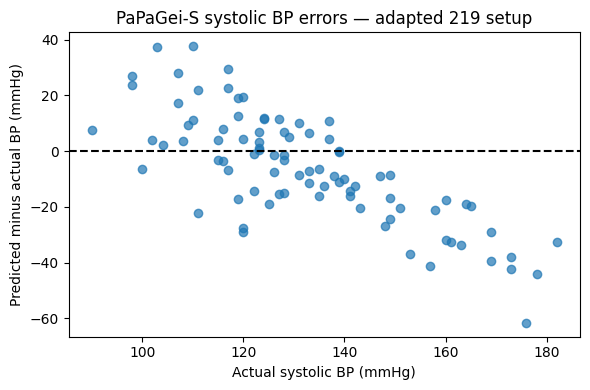

,subject_ID,split,actual_bp,predicted_bp,signed_error,absolute_error
61,197,test,176.0,114.351,-61.649,61.649
3,21,val,178.0,133.918,-44.082,44.082
14,51,val,173.0,130.710,-42.290,42.290
62,198,val,157.0,115.807,-41.193,41.193
29,111,val,169.0,129.547,-39.453,39.453


In [45]:
systolic_s = final_predictions.loc[
    final_predictions["model"].eq("papagei_s")
    & final_predictions["target"].eq("sysbp")
].copy()

assert len(systolic_s) == 88

systolic_s["signed_error"] = (
    systolic_s["predicted_bp"] - systolic_s["actual_bp"]
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(
    systolic_s["actual_bp"],
    systolic_s["signed_error"],
    alpha=0.7
)
ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("Actual systolic BP (mmHg)")
ax.set_ylabel("Predicted minus actual BP (mmHg)")
ax.set_title("PaPaGei-S systolic BP errors — adapted 219 setup")
fig.tight_layout()
plt.show()

display(
    systolic_s.nlargest(5, "absolute_error")[
        ["subject_ID", "split", "actual_bp", "predicted_bp",
         "signed_error", "absolute_error"]
    ].round(3)
)

Lower BP readings tended to be overestimated and higher readings
underestimated. Some individual errors were much larger than the overall
MAE, including an underestimation of approximately 61.65 mmHg. This illustrates why average MAE alone does not establish reliable
individual prediction.

In [46]:
#separate and combined errors are calculated from existing predictions
split_rows_219 = []

for (model_name, target), group in final_predictions.groupby(
    ["model", "target"]
):
    assert len(group) == 88
    assert group["split"].value_counts().to_dict() == {
        "val": 44, "test": 44
    }

    row = {"model": model_name, "target": target}

    for split in ["val", "test"]:
        selected = group.loc[group["split"].eq(split)]
        row[f"{split}_mae"] = mean_absolute_error(
            selected["actual_bp"], selected["predicted_bp"]
        )

    row["combined_mae"] = mean_absolute_error(
        group["actual_bp"], group["predicted_bp"]
    )
    split_rows_219.append(row)

split_comparison_219 = pd.DataFrame(split_rows_219)
display(split_comparison_219.round(3))

,model,target,val_mae,test_mae,combined_mae
0,papagei_p,diasbp,9.646,8.853,9.250
1,papagei_p,sysbp,15.115,15.159,15.137
2,papagei_s,diasbp,9.023,9.062,9.043
3,papagei_s,sysbp,16.778,15.917,16.347


## 7. Classification reproduction

Normal BP is labelled 0. Pre-hypertension and both hypertension stages
are grouped as non-normal BP and labelled 1.

Logistic regression is tuned using accuracy. The original 205-participant
setup retains scaling before cross-validation. The adapted 219-participant
setup uses scaling inside the pipeline and stratified grouped folds.

AUROC is calculated from predicted probabilities. Accuracy and F1 use
the classifier's default predicted labels, without threshold tuning.

In [ ]:
#this cell defines classification helpers
label_mapping = {
    "Normal": 0,
    "Prehypertension": 1,
    "Stage 1 hypertension": 1,
    "Stage 2 hypertension": 1
}

logistic_grid = {
    "penalty": ["l2"],
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs"],
    "max_iter": [100, 200]
}


def binary_labels(values):
    mapped = pd.Series(np.asarray(values)).map(label_mapping)
    assert mapped.notna().all()
    return mapped.to_numpy(dtype=int)


def classification_metrics(y_true, probabilities, predictions):
    #500 valid participant resamples are used for the AUROC interval
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    rng = np.random.default_rng(42)
    bootstrap_auc = []

    while len(bootstrap_auc) < 500:
        indices = rng.integers(0, len(y_true), size=len(y_true))
        if np.unique(y_true[indices]).size == 2:
            bootstrap_auc.append(
                roc_auc_score(y_true[indices], probabilities[indices])
            )

    lower, upper = np.percentile(bootstrap_auc, [2.5, 97.5])

    return {
        "auroc": roc_auc_score(y_true, probabilities),
        "ci_lower": lower,
        "ci_upper": upper,
        "accuracy": accuracy_score(y_true, predictions),
        "f1": f1_score(y_true, predictions, zero_division=0)
    }


def load_original_classification(model_name, split):
    embeddings = joblib.load(
        Path(download_dir) / "features" / model_name
        / f"dict_{split}_patient.p"
    )

    #dictionary order is retained to match the original classification run
    ids = [int(key) for key in embeddings]
    frame = original_splits[split].set_index("subject_ID")

    arrays = []
    for value in embeddings.values():
        if hasattr(value, "detach"):
            value = value.detach().cpu().numpy()
        arrays.append(np.asarray(value).reshape(-1))

    X = np.stack(arrays)
    y = binary_labels(frame.loc[ids, "Hypertension"])
    return X, y, ids

In [ ]:
#Loads the saved 205 results or refits logistic regression 
#using the original ordering and scaling before CV.
if RECOMPUTE_CLASSIFICATION:
    classification_rows_205 = []
    classification_prediction_tables_205 = []

    for model_name in models:
        X_train, y_train, _ = load_original_classification(
            model_name, "train"
        )
        X_test, y_test, test_ids = load_original_classification(
            model_name, "test"
        )
        X_val, y_val, val_ids = load_original_classification(
            model_name, "val"
        )

        X_eval = np.concatenate([X_test, X_val])
        y_eval = np.concatenate([y_test, y_val])
        eval_ids = np.asarray(test_ids + val_ids)

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_eval_scaled = scaler.transform(X_eval)

        search = GridSearchCV(
            LogisticRegression(),
            logistic_grid,
            cv=4,
            scoring="accuracy",
            n_jobs=-1,
            error_score="raise"
        )
        search.fit(X_train_scaled, y_train)

        probabilities = search.predict_proba(X_eval_scaled)[:, 1]
        predictions = search.predict(X_eval_scaled)

        #sorting matches the participant order used for the saved bootstrap
        order = np.argsort(eval_ids)
        metrics = classification_metrics(
            y_eval[order], probabilities[order], predictions[order]
        )

        classification_rows_205.append({
            "model": model_name,
            "n_train": len(y_train),
            "n_evaluation": len(y_eval),
            **metrics,
            **search.best_params_
        })

        classification_prediction_tables_205.append(pd.DataFrame({
            "subject_ID": eval_ids,
            "split": ["test"] * len(test_ids) + ["val"] * len(val_ids),
            "model": model_name,
            "actual_label": y_eval,
            "predicted_label": predictions,
            "probability_non_normal": probabilities
        }))

    classification_results_205 = pd.DataFrame(classification_rows_205)
    classification_predictions_205 = pd.concat(
        classification_prediction_tables_205, ignore_index=True
    )
else:
    classification_results_205 = pd.read_csv(
        classification_205_dir / "classification_results_with_ci.csv"
    )
    classification_predictions_205 = pd.read_csv(
        classification_205_dir / "classification_predictions.csv"
    )

display(classification_results_205[
    ["model", "auroc", "ci_lower", "ci_upper", "accuracy", "f1"]
].round(3))

,model,auroc,ci_lower,ci_upper,accuracy,f1
0,papagei_s,0.758,0.647,0.861,0.732,0.807
1,papagei_p,0.638,0.505,0.766,0.659,0.736


In [ ]:
if RECOMPUTE_CLASSIFICATION:
    classification_rows_219 = []

    y_train = binary_labels(training_data["Hypertension"])
    y_eval = binary_labels(evaluation_data["Hypertension"])
    groups = training_data["group"].to_numpy()

    classification_cv = list(
        StratifiedGroupKFold(n_splits=4, shuffle=False).split(
            training_data, y_train, groups
        )
    )

    # Shared-recording groups must remain separated in every CV fold.
    for fit_idx, check_idx in classification_cv:
        assert set(groups[fit_idx]).isdisjoint(groups[check_idx])
        assert np.unique(y_train[fit_idx]).size == 2
        assert np.unique(y_train[check_idx]).size == 2

    for model_name in models:
        X_train = embedding_matrix(
            embeddings_219[model_name],
            training_data["subject_ID"]
        )
        X_eval = embedding_matrix(
            embeddings_219[model_name],
            evaluation_data["subject_ID"]
        )

        search = GridSearchCV(
            Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", LogisticRegression())
            ]),
            {
                f"classifier__{key}": values
                for key, values in logistic_grid.items()
            },
            cv=classification_cv,
            scoring="accuracy",
            n_jobs=-1,
            error_score="raise"
        )
        search.fit(X_train, y_train)

        probabilities = search.predict_proba(X_eval)[:, 1]
        predictions = search.predict(X_eval)

        classification_rows_219.append({
            "model": model_name,
            "n_train": len(y_train),
            "n_evaluation": len(y_eval),
            **classification_metrics(y_eval, probabilities, predictions)
        })

    classification_results_219 = pd.DataFrame(classification_rows_219)
else:
    classification_results_219 = pd.read_csv(
        results_219_dir / "hypertension_paper_comparison.csv"
    )

# Both intervals are shown so the discussion can be assessed from this table.
classification_setup_comparison = classification_results_205[
    ["model", "auroc", "ci_lower", "ci_upper"]
].rename(columns={key: f"{key}_205" for key in ["auroc", "ci_lower", "ci_upper"]}).merge(
    classification_results_219[["model", "auroc", "ci_lower", "ci_upper"]].rename(
        columns={key: f"{key}_219" for key in ["auroc", "ci_lower", "ci_upper"]}
    ), on="model", validate="one_to_one"
)
classification_setup_comparison["paper_auroc"] = classification_setup_comparison["model"].map(
    {"papagei_s": 0.77, "papagei_p": 0.74}
)
classification_setup_display = classification_setup_comparison[["model", "paper_auroc"]].copy()
for setup in ["205", "219"]:
    classification_setup_display[f"{setup} AUROC (95% CI)"] = classification_setup_comparison.apply(
        lambda row: f"{row[f'auroc_{setup}']:.3f} [{row[f'ci_lower_{setup}']:.3f}, {row[f'ci_upper_{setup}']:.3f}]",
        axis=1
    )
display(classification_setup_display.round(3))

PaPaGei-S almost reproduced its published AUROC in the original
205-participant setup, while PaPaGei-P obtained a lower value.
The model ranking reversed in the adapted 219-participant setup.

Confidence intervals were wide. The results support useful discriminatory
information in the embeddings but do not establish a consistent advantage
for either model across the two setups.

In [ ]:
#Shows original hypertension categories across the adapted split
#the hypertension labels are matched to the existing participant split
assert labels["subject_ID"].is_unique

classification_data = (
    new_split[["subject_ID", "split", "group"]]
    .merge(
        labels[["subject_ID", "Hypertension"]],
        on="subject_ID",
        how="left",
        validate="one_to_one"
    )
    .sort_values("subject_ID")
    .reset_index(drop=True)
)

#all 219 participants are checked for missing labels
assert len(classification_data) == 219
assert classification_data["Hypertension"].notna().all()

#the original categories are counted before being converted to binary labels
display(pd.crosstab(
    classification_data["Hypertension"],
    classification_data["split"],
    margins=True
))

split,test,train,val,All
Hypertension,,,,
Normal,12,55,13,80
Prehypertension,15,49,21,85
Stage 1 hypertension,9,20,5,34
Stage 2 hypertension,8,7,5,20
All,44,131,44,219


#### Classification reflection

In the saved 205-participant run, PaPaGei-S reached AUROC 0.758 versus 0.770 in the paper; PaPaGei-P reached 0.638 versus 0.740. In the adapted 219 setup, S reached 0.641 and P reached 0.708, reversing the ranking.

The displayed 95% intervals are wide. They were estimated with 500 participant bootstrap resamples while keeping each fitted model fixed; they do not measure variation from retraining or uncertainty in an individual's prediction. The class counts below the comparison provide context for interpreting accuracy and F1.

## 8. Baseline comparisons

Simple baselines (mean/median/majority class), random forests and MOMENT are used to assess whether
PaPaGei provides useful improvements over simpler or general-purpose
alternatives.

Regression baselines are compared on both participant setups.
Classification baselines and MOMENT are evaluated on the original
205-participant split.

### 8.1 Constant blood pressure predictors

Training-set mean and median BP values are predicted for every evaluation
participant. No PPG information is used.

In [ ]:
#the original participant split is reconstructed
split_205 = pd.concat([
    frame[["subject_ID"]].assign(split=split)
    for split, frame in original_splits.items()
], ignore_index=True)

baseline_data_205 = split_205.merge(
    label_data[["subject_ID", "sysbp", "diasbp", "Hypertension"]],
    on="subject_ID",
    validate="one_to_one"
)

baseline_datasets = {
    "205": baseline_data_205,
    "219": adapted_data
}


def calculate_constant_baselines(frame):
    train = frame.loc[frame["split"].eq("train")]
    evaluation = frame.loc[
        frame["split"].isin(["val", "test"])
    ]

    rows = []

    for target in bp_targets:
        constants = {
            "training_mean": train[target].mean(),
            "training_median": train[target].median()
        }

        for model_name, constant in constants.items():
            rows.append({
                "model": model_name,
                "target": target,
                "constant_prediction": constant,
                "n_train": len(train),
                "n_evaluation": len(evaluation),
                "mae": np.abs(
                    evaluation[target].to_numpy() - constant
                ).mean()
            })

    return pd.DataFrame(rows)


constant_results = {
    setup: calculate_constant_baselines(frame)
    for setup, frame in baseline_datasets.items()
}

# The PaPaGei scores already selected or recomputed above are reused.
papagei_bp_results = {
    "205": original_results_table.loc[original_results_table["target"].isin(bp_targets), ["model", "target", "mae"]].copy(),
    "219": final_results[["model", "target", "mae"]].copy()
}

def compare_bp_models(baseline_results):
    parts = []
    for setup in ["205", "219"]:
        combined = pd.concat([
            papagei_bp_results[setup],
            baseline_results[setup][["model", "target", "mae"]]
        ], ignore_index=True)
        assert not combined.duplicated(["model", "target"]).any()
        parts.append(combined.assign(setup=setup))
    return pd.concat(parts, ignore_index=True).pivot(
        index=["setup", "model"], columns="target", values="mae"
    ).reindex(columns=bp_targets).rename(columns={
        "sysbp": "Systolic MAE (mmHg)", "diasbp": "Diastolic MAE (mmHg)"
    }).rename_axis(columns=None)

constant_comparison = compare_bp_models(constant_results)
display(constant_comparison.round(3))

,model,target,constant_prediction,n_train,n_evaluation,mae,setup
0,training_mean,sysbp,127.252,123,82,15.799,205
1,training_median,sysbp,127.000,123,82,15.768,205
2,training_mean,diasbp,71.894,123,82,9.372,205
3,training_median,diasbp,71.000,123,82,9.220,205
4,training_mean,sysbp,125.107,131,88,16.770,219
5,training_median,sysbp,124.000,131,88,16.943,219
6,training_mean,diasbp,71.130,131,88,8.543,219
7,training_median,diasbp,70.000,131,88,8.602,219


It can be observed that for systolic BP predicitons, both PaPaGei types perform significantly better, however they performed much worse for diastolic BP compared to basic mean/median baseline. This could be because the embeddings may contain limited info on diastolic BP, or they might also be some noise fitted as there is 512 features and 131 training participants.

### 8.2 Statistical features and random-forest regression

Seven features are extracted from each padded recording: mean, standard
deviation, three percentiles, minimum and maximum. 

In this implementation, both the 205- and 219-participant statistical
baselines use the duplicate-cleaned padded recordings. The 205-participant
baseline retains the released participant split, but its recording handling differs from the original PaPaGei embedding extraction.

Random forests are tuned using four grouped folds and mean squared error.

In [55]:
feature_names = [
    "mean", "std", "percentile_25", "percentile_50",
    "percentile_75", "minimum", "maximum"
]

clean_ppg_dir = experiment_dir / "ppg"

#one retained recording is inspected for padding effects
sample_path = sorted(clean_ppg_dir.glob("*/*.p"))[0]
sample_signal = np.asarray(joblib.load(sample_path)).squeeze()

print("Inspected file:", sample_path)
print("Proportion of zeros:", np.mean(sample_signal == 0))
print("Percentiles:", np.percentile(sample_signal, [25, 50, 75]))


def calculate_statistical_features(participant_ids):
    recording_rows = []

    for participant in sorted(participant_ids):
        folder = f"{int(participant):04d}"
        files = sorted((clean_ppg_dir / folder).glob("*.p"))
        assert files, f"No processed recordings for {participant}"

        for path in files:
            recording_rows.append({
                "subject_ID": folder,
                "segments": path.name
            })

    recordings = pd.DataFrame(recording_rows)

    feature_dict = compute_signal_statistics_df(
        df=recordings,
        path=str(clean_ppg_dir),
        case_name="subject_ID"
    )

    features = (
        pd.DataFrame.from_dict(
            feature_dict, orient="index", columns=feature_names
        )
        .rename_axis("subject_ID")
        .reset_index()
    )
    features["subject_ID"] = features["subject_ID"].astype(int)
    return features


stat_features = {}

for setup, frame in baseline_datasets.items():
    if RECOMPUTE_STATISTICAL_FEATURES:
        stat_features[setup] = calculate_statistical_features(
            frame["subject_ID"]
        )
    else:
        stat_features[setup] = pd.read_csv(
            baseline_results_dir / f"statistical_features_padded_{setup}.csv"
        )

    assert np.isfinite(
        stat_features[setup][feature_names].to_numpy()
    ).all()

Inspected file: data_PPG\reproduction_219_seed42\ppg\0002\1.p
Proportion of zeros: 0.7896
Percentiles: [0. 0. 0.]


Padding dominated in this inspected recording (its three percentiles being 
zero) This may reduce the usefulness of amplitude-based statistical
features and limits interpretation of the random-forest comparison.

In [8]:
rf_regression_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3, 5],
    "max_features": [1.0, "sqrt"]
}


def fit_rf_regression(frame, features, setup):
    matched = (
        frame.merge(
            features[["subject_ID"] + feature_names],
            on="subject_ID",
            validate="one_to_one"
        )
        .sort_values("subject_ID")
        .reset_index(drop=True)
    )

    train = matched.loc[matched["split"].eq("train")]
    evaluation = matched.loc[
        matched["split"].isin(["val", "test"])
    ]

    group_column = "group" if setup == "219" else "subject_ID"
    rows = []

    for target in bp_targets:
        search = GridSearchCV(
            RandomForestRegressor(random_state=42, n_jobs=1),
            rf_regression_grid,
            cv=GroupKFold(n_splits=4),
            scoring="neg_mean_squared_error",
            n_jobs=-1,
            error_score="raise"
        )

        search.fit(
            train[feature_names].to_numpy(),
            train[target].to_numpy(),
            groups=train[group_column].to_numpy()
        )

        predictions = search.predict(
            evaluation[feature_names].to_numpy()
        )

        rows.append({
            "model": "random_forest_padded",
            "target": target,
            "n_train": len(train),
            "n_evaluation": len(evaluation),
            "mae": mean_absolute_error(evaluation[target], predictions),
            **search.best_params_
        })

    return pd.DataFrame(rows)


rf_regression_results = {}

for setup in ["205", "219"]:
    if RECOMPUTE_RF_REGRESSION:
        rf_regression_results[setup] = fit_rf_regression(
            baseline_datasets[setup],
            stat_features[setup],
            setup
        )
    else:
        filename = (
            "random_forest_padded_results_205.csv"
            if setup == "205"
            else "random_forest_padded_results.csv"
        )
        rf_regression_results[setup] = pd.read_csv(
            baseline_results_dir / filename
        )

# Saved PaPaGei results are loaded for the corresponding setups.
papagei_regression_results = {
    "205": pd.read_csv(Path("results") / "reproduction_results.csv"),
    "219": pd.read_csv(results_219_dir / "final_bp_results.csv")
}

comparison_parts = []

for setup in ["205", "219"]:
    # Only the two PaPaGei variants and BP targets are selected.
    papagei = papagei_regression_results[setup]
    papagei = papagei.loc[
        papagei["model"].isin(models)
        & papagei["target"].isin(bp_targets),
        ["model", "target", "mae"]
    ]

    # Each model–target pair must have exactly one result.
    assert not papagei.duplicated(["model", "target"]).any()
    assert len(papagei) == len(models) * len(bp_targets)

    comparison_parts.append(
        pd.concat([
            rf_regression_results[setup][["model", "target", "mae"]],
            papagei
        ], ignore_index=True).assign(setup=setup)
    )

# Systolic and diastolic MAEs are displayed side by side.
rf_papagei_comparison = (
    pd.concat(comparison_parts, ignore_index=True)
    .pivot(index=["setup", "model"], columns="target", values="mae")
    .reindex(columns=bp_targets)
    .rename(columns={
        "sysbp": "Systolic MAE (mmHg)",
        "diasbp": "Diastolic MAE (mmHg)"
    })
    .rename_axis(columns=None)
)

display(rf_papagei_comparison.round(3))

Systolic MAE (mmHg)  Diastolic MAE (mmHg)
setup model                                                          
205   papagei_p                          14.307                 8.882
      papagei_s                          14.254                 8.910
      random_forest_padded               15.194                 9.225
219   papagei_p                          15.137                 9.250
      papagei_s                          16.347                 9.043
      random_forest_padded               16.269                 8.136

Both PaPaGei variants achieved lower regression errors than random forest
on the original 205-participant split. In the adapted setup, random forest
achieved the lowest diastolic MAE, while PaPaGei-P achieved the lowest
systolic MAE.

### 8.3 Classification baselines

The majority predictor assigns the most frequent training class to every
evaluation participant. Random forest uses the statistical features and
the released classification grid, with accuracy for model selection.

The saved random-forest classification result is retained by default (original code omitted usage of fixed random seed, so newly fitted forest might perform differently). 

In [57]:
#the original train-validation-test ordering is retained
classification_frame = baseline_data_205.merge(
    stat_features["205"][["subject_ID"] + feature_names],
    on="subject_ID",
    validate="one_to_one"
)

cls_train = classification_frame.loc[
    classification_frame["split"].eq("train")
]
cls_eval = classification_frame.loc[
    classification_frame["split"].isin(["val", "test"])
]

y_train_cls = binary_labels(cls_train["Hypertension"])
y_eval_cls = binary_labels(cls_eval["Hypertension"])

majority_class = int(pd.Series(y_train_cls).mode().iloc[0])
majority_predictions = np.full(len(y_eval_cls), majority_class)
majority_probabilities = np.full(len(y_eval_cls), y_train_cls.mean())

majority_results = pd.DataFrame([{
    "model": "majority_class",
    "auroc": roc_auc_score(y_eval_cls, majority_probabilities),
    "ci_lower": np.nan,
    "ci_upper": np.nan,
    "accuracy": accuracy_score(y_eval_cls, majority_predictions),
    "f1": f1_score(y_eval_cls, majority_predictions, zero_division=0)
}])

if RECOMPUTE_RF_CLASSIFICATION:
    scaler = StandardScaler()
    X_train = scaler.fit_transform(cls_train[feature_names])
    X_eval = scaler.transform(cls_eval[feature_names])

    #a fixed seed is used for a new verification run
    #this does not recreate the historical unseeded forest exactly
    search = GridSearchCV(
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_features": ["sqrt", "log2"],
            "max_depth": [10, 20, 30],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2]
        },
        cv=4,
        scoring="accuracy",
        n_jobs=-1,
        error_score="raise"
    )
    search.fit(X_train, y_train_cls)

    probabilities = search.predict_proba(X_eval)[:, 1]
    predictions = search.predict(X_eval)

    rf_classification_results = pd.DataFrame([{
        "model": "random_forest_padded",
        **classification_metrics(
            y_eval_cls, probabilities, predictions
        )
    }])
else:
    rf_classification_results = pd.read_csv(
        baseline_results_dir / "hypertension_random_forest_results_205.csv"
    ).rename(columns={
        "auc_lower_ci": "ci_lower",
        "auc_upper_ci": "ci_upper"
    })

display(majority_results.round(3))
display(rf_classification_results[
    ["model", "auroc", "ci_lower", "ci_upper", "accuracy", "f1"]
].round(3))

,model,auroc,ci_lower,ci_upper,accuracy,f1
0,majority_class,0.5,NaN,NaN,0.634,0.776


,model,auroc,ci_lower,ci_upper,accuracy,f1
0,random_forest_padded,0.603,0.465,0.744,0.671,0.765


The majority class achieved a high F1 score despite
having an AUROC of 0.5 (no doscriminatory ability). This reflects the prevalence of the
non-normal class and shows why accuracy and F1 should be interpreted
alongside AUROC.

PaPaGei-S exceeded the majority baseline across all three metrics.
Both PaPaGei variants had higher observed AUROC than random forest. 

### 8.4 MOMENT comparison

MOMENT-1-large is evaluated as a general-purpose foundation-model baseline
using saved 1024-dimensional participant embeddings.

Ridge regression uses the original extended regularisation grid.
Logistic regression uses the same valid parameter grid as the original
PaPaGei classification experiment. Scaling is fitted before cross-validation
to match the original runs.

This section can load the saved results or refit the downstream models
from saved embeddings.

In [58]:
moment_save_dir = Path(download_dir) / "features" / "moment"
moment_data = {}

for split in ["train", "val", "test"]:
    embeddings = joblib.load(
        moment_save_dir / f"dict_{split}_patient.p"
    )

    #numeric keys are used to match labels explicitly
    embeddings_by_id = {
        int(key): np.asarray(value).reshape(-1)
        for key, value in embeddings.items()
    }

    frame = (
        original_splits[split][["subject_ID"]]
        .merge(
            label_data[
                ["subject_ID", "sysbp", "diasbp", "Hypertension"]
            ],
            on="subject_ID",
            validate="one_to_one"
        )
        .sort_values("subject_ID")
        .reset_index(drop=True)
    )

    ids = frame["subject_ID"].to_numpy(dtype=int)

    moment_data[split] = {
        "subject_ID": ids,
        "X": np.stack([embeddings_by_id[pid] for pid in ids]),
        "sysbp": frame["sysbp"].to_numpy(dtype=float),
        "diasbp": frame["diasbp"].to_numpy(dtype=float),
        "hypertension": binary_labels(frame["Hypertension"])
    }

#test followed by validation matches the saved regression procedure
moment_data["eval"] = {
    key: np.concatenate([
        moment_data["test"][key],
        moment_data["val"][key]
    ])
    for key in moment_data["train"]
}

assert moment_data["train"]["X"].shape == (123, 1024)
assert moment_data["eval"]["X"].shape == (82, 1024)

print("Training embeddings:", moment_data["train"]["X"].shape)
print("Evaluation embeddings:", moment_data["eval"]["X"].shape)

Training embeddings: (123, 1024)
Evaluation embeddings: (82, 1024)


In [59]:
#Regression
if RECOMPUTE_MOMENT_MODELS:
    moment_rows = []

    for target in bp_targets:
        #the seed matches the saved MOMENT regression procedure
        np.random.seed(42)

        result = regression_model(
            estimator=Ridge(),
            param_grid={
                "alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
                "solver": ["auto", "cholesky", "sparse_cg"]
            },
            X_train=moment_data["train"]["X"],
            y_train=moment_data["train"][target],
            X_test=moment_data["eval"]["X"],
            y_test=moment_data["eval"][target]
        )

        moment_rows.append({
            "model": "moment",
            "target": target,
            "mae": result["mae"],
            "ci_lower": result["lower_bound_mae"],
            "ci_upper": result["upper_bound_mae"],
            "r2": result["r2"],
            "alpha": result["parameters"]["alpha"],
            "solver": result["parameters"]["solver"]
        })

    moment_regression_results = pd.DataFrame(moment_rows)
else:
    moment_regression_results = pd.read_csv(
        baseline_results_dir / "moment_regression_results_205.csv"
    )

moment_regression_results["model"] = "moment"
display(moment_regression_results.round(3))

,model,target,n_train,n_evaluation,alpha,solver,mae,ci_lower,ci_upper,r2,r2_ci_lower,r2_ci_upper
0,moment,sysbp,123,82,100.0,auto,15.572,13.140,18.125,0.006,-0.249,0.192
1,moment,diasbp,123,82,1000.0,auto,8.963,7.592,10.249,0.064,-0.062,0.134


In [60]:
#Classification
if RECOMPUTE_MOMENT_MODELS:
    #classification participants are sorted before cross-validation
    train_order = np.argsort(moment_data["train"]["subject_ID"])
    eval_order = np.argsort(moment_data["eval"]["subject_ID"])

    X_train = moment_data["train"]["X"][train_order]
    y_train = moment_data["train"]["hypertension"][train_order]
    X_eval = moment_data["eval"]["X"][eval_order]
    y_eval = moment_data["eval"]["hypertension"][eval_order]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_eval = scaler.transform(X_eval)

    search = GridSearchCV(
        LogisticRegression(),
        logistic_grid,
        cv=4,
        scoring="accuracy",
        n_jobs=-1,
        error_score="raise"
    )
    search.fit(X_train, y_train)

    probabilities = search.predict_proba(X_eval)[:, 1]
    predictions = search.predict(X_eval)

    moment_classification_results = pd.DataFrame([{
        "model": "moment",
        **classification_metrics(y_eval, probabilities, predictions),
        **search.best_params_
    }])
else:
    moment_classification_results = pd.read_csv(
        baseline_results_dir / "moment_classification_results_205.csv"
    )

display(moment_classification_results[
    ["model", "auroc", "ci_lower", "ci_upper", "accuracy", "f1"]
].round(3))

,model,auroc,ci_lower,ci_upper,accuracy,f1
0,moment,0.706,0.58,0.829,0.671,0.738


Both PaPaGei variants achieved lower BP MAEs than MOMENT (diastolic differences were small). MOMENT's low regression R² values
indicate limited improvement over predicting the evaluation-set mean
when assessed through squared error.

For classification, MOMENT's AUROC lay between PaPaGei-S and PaPaGei-P.
General-purpose embeddings therefore also contained useful information
for distinguishing BP categories.

## 9. Summary tables

The regression table combines the original 205-participant PaPaGei results
and the adapted 219-participant results with their baselines.

The classification table uses only the original 205-participant setup.
Bold values identify the best observed metric during this reproduction.

In [61]:
regression_parts = []

for setup in ["205", "219"]:
    if setup == "205":
        papagei_rows = original_results_table.loc[
            original_results_table["target"].isin(bp_targets),
            ["model", "target", "mae"]
        ]
    else:
        papagei_rows = final_results[["model", "target", "mae"]]

    parts = [
        papagei_rows,
        constant_results[setup][["model", "target", "mae"]],
        rf_regression_results[setup][["model", "target", "mae"]]
    ]

    if setup == "205":
        parts.append(
            moment_regression_results[["model", "target", "mae"]]
        )

    regression_parts.append(
        pd.concat(parts, ignore_index=True).assign(setup=setup)
    )

regression_long = pd.concat(regression_parts, ignore_index=True)

model_order = [
    "papagei_s", "papagei_p", "moment",
    "random_forest_padded", "training_mean", "training_median"
]

model_labels = {
    "papagei_s": "PaPaGei-S",
    "papagei_p": "PaPaGei-P",
    "moment": "MOMENT",
    "random_forest_padded": "Random forest",
    "training_mean": "Training mean",
    "training_median": "Training median",
    "majority_class": "Majority class"
}

regression_table = regression_long.pivot(
    index="model",
    columns=["setup", "target"],
    values="mae"
).reindex(
    index=model_order,
    columns=pd.MultiIndex.from_tuples([
        ("205", "sysbp"),
        ("205", "diasbp"),
        ("219", "sysbp"),
        ("219", "diasbp")
    ])
)

regression_table.columns = [
    "205 systolic MAE",
    "205 diastolic MAE",
    "219 systolic MAE",
    "219 diastolic MAE"
]
regression_table = regression_table.rename(index=model_labels)
regression_table.index.name = "Model"

display(
    regression_table.style
    .format("{:.3f}", na_rep="—")
    .highlight_min(axis=0, props="font-weight: bold;")
)

,205 systolic MAE,205 diastolic MAE,219 systolic MAE,219 diastolic MAE
Model,,,,
PaPaGei-S,14.254,8.910,16.347,9.043
PaPaGei-P,14.307,8.882,15.137,9.250
MOMENT,15.572,8.963,—,—
Random forest,15.194,9.225,16.269,8.136
Training mean,15.799,9.372,16.770,8.543
Training median,15.768,9.220,16.943,8.602


In [62]:
metric_columns = [
    "model", "auroc", "ci_lower", "ci_upper", "accuracy", "f1"
]

classification_numeric = pd.concat([
    classification_results_205.reindex(columns=metric_columns),
    moment_classification_results.reindex(columns=metric_columns),
    rf_classification_results.reindex(columns=metric_columns),
    majority_results.reindex(columns=metric_columns)
], ignore_index=True).set_index("model").reindex([
    "papagei_s",
    "papagei_p",
    "moment",
    "random_forest_padded",
    "majority_class"
])

classification_display = pd.DataFrame(
    index=classification_numeric.index
)

classification_display["AUROC (95% CI)"] = classification_numeric.apply(
    lambda row: (
        f"{row['auroc']:.3f} "
        f"[{row['ci_lower']:.3f}, {row['ci_upper']:.3f}]"
        if pd.notna(row["ci_lower"])
        else f"{row['auroc']:.3f}"
    ),
    axis=1
)
classification_display["Accuracy"] = classification_numeric["accuracy"]
classification_display["F1"] = classification_numeric["f1"]

classification_display = classification_display.rename(index=model_labels)
classification_display.index.name = "Model"


def highlight_classification_best(table):
    styles = pd.DataFrame("", index=table.index, columns=table.columns)

    for displayed, numeric in [
        ("AUROC (95% CI)", "auroc"),
        ("Accuracy", "accuracy"),
        ("F1", "f1")
    ]:
        best_models = classification_numeric.index[
            classification_numeric[numeric].eq(
                classification_numeric[numeric].max()
            )
        ]
        for model in best_models:
            styles.loc[model_labels[model], displayed] = "font-weight: bold;"

    return styles


display(
    classification_display.style
    .format({"Accuracy": "{:.3f}", "F1": "{:.3f}"})
    .apply(highlight_classification_best, axis=None)
)

,AUROC (95% CI),Accuracy,F1
Model,,,
PaPaGei-S,"0.758 [0.647, 0.861]",0.732,0.807
PaPaGei-P,"0.638 [0.505, 0.766]",0.659,0.736
MOMENT,"0.706 [0.580, 0.829]",0.671,0.738
Random forest,"0.603 [0.465, 0.744]",0.671,0.765
Majority class,0.500,0.634,0.776


## 10. Main findings and reproducibility notes

The original reproduction recovered BP errors close to the published values,
but the model rankings were not preserved. Changing the
regularisation grid affected some results, while moving scaling
inside cross-validation had almost no effects.

The adapted full-dataset evaluation did not improve agreement
with the paper in a consistent manner. Its differences include participant composition, duplicate
handling and cross-validation, so they cannot be attributed just to the
dataset size.

PaPaGei's regression improvements over constant and statistical baselines
were modest and depended on the target and setup. Classification showed
useful discriminatory information, particularly for PaPaGei-S in the original
205-participant setup. Large individual BP errors remained despite similar
average MAEs.

### Reproducibility notes

- Saved results are loaded by default to preserve the reported experiments.
- Recompute flags refit selected models in memory without overwriting files.
- The original random-forest classification run had no fixed random seed.
- The 205-participant statistical baseline used duplicate-cleaned recordings
  while retaining the released participant split.
- MOMENT downstream models can be refitted from the saved embeddings.

## 11. Acknowledgement of AI assistance

ChatGPT (OpenAI) was used to assist with Python code development and debugging, notebook organisation, and drafting and revising code comments. The original PaPaGei implementation and the project’s experimental results form the basis of this work. Responsibility for the submitted analysis and conclusions remains with the author.
